Persiapan Lingkungan

In [1]:
# === Persiapan 1: instalasi pustaka (Colab sudah memiliki torch dan torchvision) ===
%pip install -q transformers

In [2]:
# === Persiapan 2: impor, cek GPU, seed, dan konfigurasi ===
import os, time, random, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"   # tanpa GPU: jalankan versi diperkecil
print("PyTorch", torch.__version__, "| torchvision",
torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE ==
"cuda" else "CPU saja")

CFG = dict(
    IMG     = 128 if CEPAT else 256,   # ukuran sisi citra (piksel)
    N_TRAIN = 320 if CEPAT else 2000,  # jumlah citra latih (dari daftar trainval resmi)
    N_TEST  = 100 if CEPAT else 500,   # jumlah citra uji (dari daftar test resmi)
    BATCH   = 16,
    EP_UNET = 6 if CEPAT else 15,
    EP_DLV3 = 2 if CEPAT else 6,
    EP_SEGF = 3 if CEPAT else 6,
    BASE_CH = 16 if CEPAT else 32,     # lebar kanal U-Net
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}   # catatan waktu tiap bagian

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}


Praktikum D1: Mengenal Data Segmentasi (Oxford-IIIT Pet)

In [4]:
#=== D1.1 Unduh subset Oxford-IIIT Pet (Versi Diperbarui & Aman) ===
import tarfile, urllib.request, os, time
URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    if os.path.exists(ann) and os.path.getsize(ann) < 1000:
        os.remove(ann)
    if not os.path.exists(ann):
        print("Mengunduh file anotasi...")
        req = urllib.request.Request(URL_ANN, headers=headers)
        with urllib.request.urlopen(req) as resp, open(ann, 'wb') as f:
            f.write(resp.read())
    split, trimaps = {}, {}
    print("Membaca data anotasi...")
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/trainval.txt") or m.name.endswith("annotations/test.txt"):
                s = "train" if "trainval" in m.name else "test"
                for line in t.extractfile(m).read().decode().splitlines():
                    if line.strip():
                        parts = line.split()
                        if parts:
                            split[parts[0]] = s
            elif "/trimaps/" in m.name and m.name.endswith(".png") and not os.path.basename(m.name).startswith('.'):
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()

    def hitung():
        ada = [f[:-4] for f in os.listdir(f"{root}/images") if f.endswith(".jpg")]
        return sorted(i for i in ada if split.get(i) == "train"), sorted(i for i in ada if split.get(i) == "test")

    tr, te = hitung()
    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia lengkap di", root)
        return tr[:n_train], te[:n_test]

    print("Mengunduh arsip citra (proses ini memakan waktu beberapa saat)...")
    req_img = urllib.request.Request(URL_IMG, headers=headers)
    with urllib.request.urlopen(req_img) as resp, tarfile.open(fileobj=resp, mode="r:gz") as t:
        for m in t:
            nama = os.path.basename(m.name)
            if not nama.endswith(".jpg"):
                continue
            iid = nama[:-4]
            s = split.get(iid)
            if iid not in trimaps or s is None:
                continue
            if (s == "train" and len(tr) >= n_train) or (s == "test" and len(te) >= n_test):
                continue

            img_path = f"{root}/images/{nama}"
            tri_path = f"{root}/trimaps/{iid}.png"

            if not os.path.exists(img_path):
                with open(img_path, "wb") as f:
                    f.write(t.extractfile(m).read())
            if not os.path.exists(tri_path):
                with open(tri_path, "wb") as f:
                    f.write(trimaps[iid])

            tr, te = hitung()
            if len(tr) >= n_train and len(te) >= n_test:
                break

    tr, te = hitung()
    return tr[:n_train], te[:n_test]

t0 = time.time()
ROOT = "data/pet_subset"
ID_TRAIN, ID_TEST = ambil_subset_pet(ROOT, CFG["N_TRAIN"], CFG["N_TEST"])
print(f"Citra latih: {len(ID_TRAIN)} | citra uji: {len(ID_TEST)} | waktu {time.time()-t0:.1f} detik")
print("Jumlah ras pada data latih:", len(set(i.rsplit('_', 1)[0] for i in ID_TRAIN)))

Mengunduh file anotasi...
Membaca data anotasi...
Mengunduh arsip citra (proses ini memakan waktu beberapa saat)...
Citra latih: 2000 | citra uji: 500 | waktu 23.0 detik
Jumlah ras pada data latih: 37


In [5]:
#=== D1.2 Dataset PyTorch: citra RGB + masker biner + masker valid ===
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def muat_pasangan(iid, size):
    img = Image.open(f"{ROOT}/images/{iid}.jpg").convert("RGB").resize((size, size), Image.BILINEAR)
    tri = Image.open(f"{ROOT}/trimaps/{iid}.png").resize((size, size), Image.NEAREST)
    return np.array(img), np.array(tri)

class PetSegDataset(torch.utils.data.Dataset):
    # Semua data dimuat sekali ke memori dalam bentuk uint8 agar pelatihan cepat
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)  # (N,3,H,W) uint8
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs])) # (N,H,W) uint8
        self.augment = augment
    def __len__(self):
        return len(self.img)
    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0)        # 1 = hewan, 0 = latar
        valid = (tri != 3).float().unsqueeze(0)    # 0 pada piksel batas (diabaikan)
        if self.augment and random.random() < 0.5: # augmentasi: horizontal flip
            x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)
        return (x - MEAN) / STD, y, valid


t0 = time.time()
ds_train = PetSegDataset(ID_TRAIN, CFG["IMG"], augment=True)
ds_test = PetSegDataset(ID_TEST, CFG["IMG"], augment=False)
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=CFG["BATCH"], shuffle=True)
dl_test = torch.utils.data.DataLoader(ds_test, batch_size=CFG["BATCH"], shuffle=False)
x, y, v = ds_train[0]
print("Bentuk x:", tuple(x.shape), " | y:", tuple(y.shape), " | valid:", tuple(v.shape))
tri_all = ds_train.tri
print("Proporsi piksel hewan: %.3f | latar: %.3f | batas: %.3f" % tuple(((tri_all == k).float().mean().item()) for k in (1, 2, 3)))
WAKTU["D1 data"] = time.time() - t0

Bentuk x: (3, 256, 256)  | y: (1, 256, 256)  | valid: (1, 256, 256)
Proporsi piksel hewan: 0.301 | latar: 0.584 | batas: 0.114


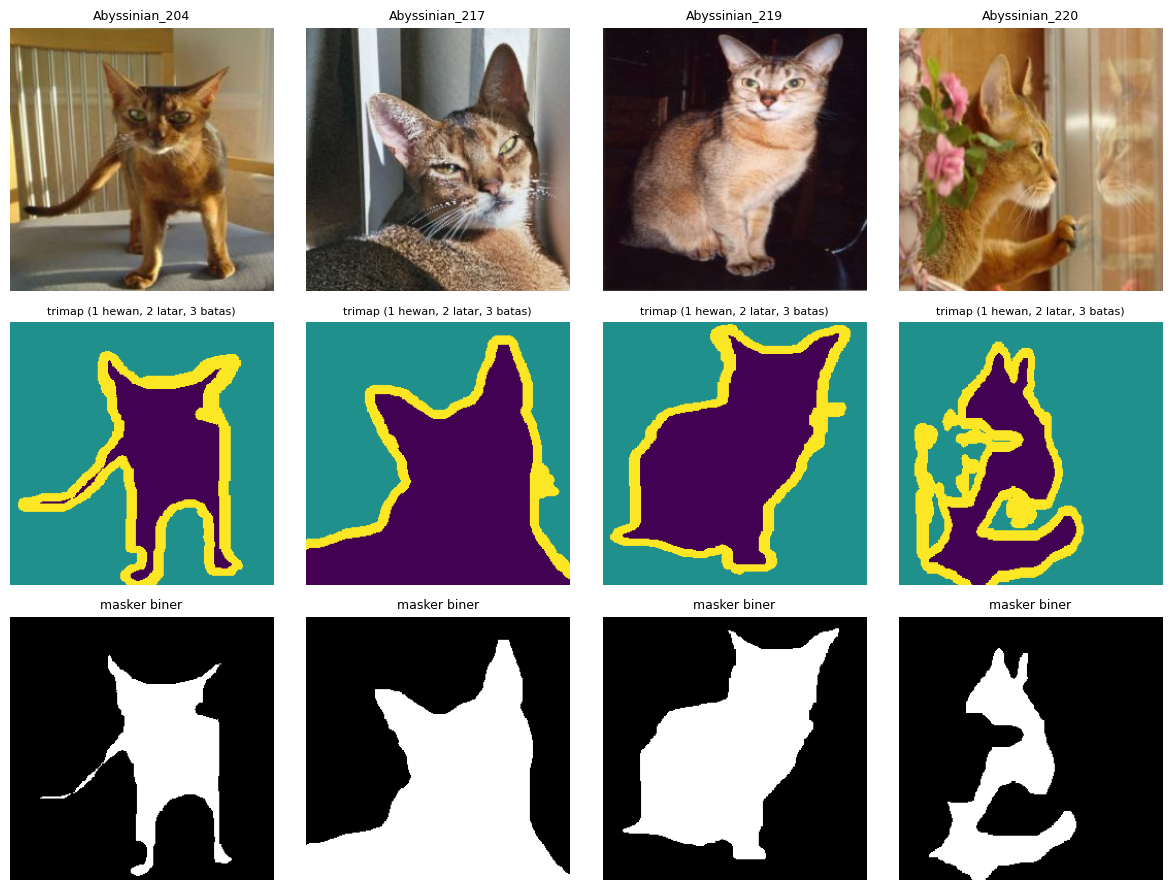

In [24]:
# === D1.3 Visualisasi: citra, trimap, dan masker biner ===
def denorm(x):
  return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for k in range(4):
  x, y, v = ds_test[k]
  ax[0, k].imshow(denorm(x)); ax[0, k].set_title(ID_TEST[k], fontsize=9)
  ax[1, k].imshow(ds_test.tri[k], cmap="viridis", vmin=1, vmax=3); ax[1, k].set_title("trimap (1 hewan, 2 latar, 3 batas)", fontsize=8)
  ax[2, k].imshow(y[0], cmap="gray"); ax[2, k].set_title("masker biner", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d1_contoh_data.png",
dpi=120); plt.show()

Praktikum D2: Membangun dan Melatih U-Net dari Nol

In [7]:
# === D2.1 Arsitektur U-Net kecil ===
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i+1]) for i in range(4)])
        self.up  = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(c[i]*2, c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)
    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop()                       # bottleneck
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1))   # skip connection
        return self.head(x)                   # logit (B,1,H,W)

unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)
print("Jumlah parameter U-Net: %.2f juta" % (sum(p.numel() for p in unet.parameters()) / 1e6))
print("Uji bentuk keluaran:", tuple(unet(torch.zeros(2, 3, CFG["IMG"], CFG["IMG"], device=DEVICE)).shape))

Jumlah parameter U-Net: 7.76 juta
Uji bentuk keluaran: (2, 1, 256, 256)


In [8]:
# === D2.2 Loss BCE + Dice dengan masker valid, dan fungsi pelatihan umum ===
def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)
    p = torch.sigmoid(logit) * valid
    inter = (p * y * valid).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum(dim=(1, 2, 3)) + (y * valid).sum(dim=(1, 2, 3)) + eps)
    return bce + w_dice * dice.mean()

def latih(model, forward, epochs, lr, nama, param_groups=None):
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_dice_loss(forward(model, x), y, v)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        model.eval(); tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v).item() * len(x)
        riwayat["train"].append(tot / len(ds_train));
        riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs}  loss latih {riwayat['train'][-1]:.4f}  loss uji {riwayat['test'][-1]:.4f} ({time.time()-t0:.0f} s)")
    WAKTU[nama] = time.time() - t0
    return riwayat

fwd_unet = lambda m, x: m(x)
set_seed(42)
hist_unet = latih(unet, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (dari nol)")

[U-Net (dari nol)] epoch 1/15  loss latih 0.9146  loss uji 0.7120 (48 s)
[U-Net (dari nol)] epoch 2/15  loss latih 0.7412  loss uji 0.9098 (97 s)
[U-Net (dari nol)] epoch 3/15  loss latih 0.6516  loss uji 0.6105 (146 s)
[U-Net (dari nol)] epoch 4/15  loss latih 0.5934  loss uji 0.5644 (195 s)
[U-Net (dari nol)] epoch 5/15  loss latih 0.5510  loss uji 0.6911 (244 s)
[U-Net (dari nol)] epoch 6/15  loss latih 0.5110  loss uji 0.5251 (292 s)
[U-Net (dari nol)] epoch 7/15  loss latih 0.4698  loss uji 0.5142 (341 s)
[U-Net (dari nol)] epoch 8/15  loss latih 0.4279  loss uji 0.4612 (390 s)
[U-Net (dari nol)] epoch 9/15  loss latih 0.4226  loss uji 0.3855 (439 s)
[U-Net (dari nol)] epoch 10/15  loss latih 0.3793  loss uji 0.3646 (488 s)
[U-Net (dari nol)] epoch 11/15  loss latih 0.3603  loss uji 0.3525 (537 s)
[U-Net (dari nol)] epoch 12/15  loss latih 0.3524  loss uji 0.3381 (586 s)
[U-Net (dari nol)] epoch 13/15  loss latih 0.3350  loss uji 0.4041 (635 s)
[U-Net (dari nol)] epoch 14/15  loss

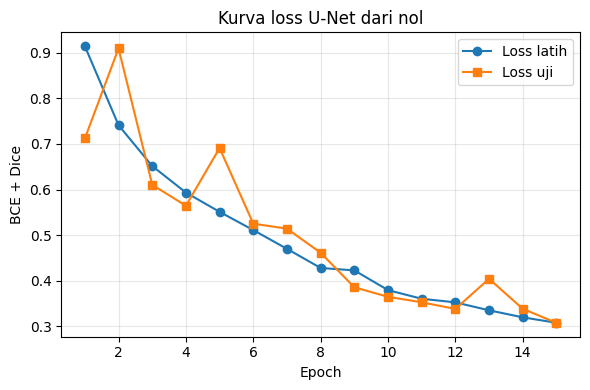

In [9]:
# === D2.3 Kurva loss U-Net ===
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["train"]) + 1)
plt.plot(ep, hist_unet["train"], "o-", label="Loss latih")
plt.plot(ep, hist_unet["test"], "s-", label="Loss uji")
plt.xlabel("Epoch"); plt.ylabel("BCE + Dice"); plt.title("Kurva loss U-Net dari nol"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d2_kurva_unet.png", dpi=120); plt.show()

In [12]:
#=== Eksperimen Tugas Kecil D2: Melatih U-Net dengan w_dice = 0 (Hanya BCE) ===
set_seed(42)
unet_bce = UNet(base=CFG["BASE_CH"]).to(DEVICE)

def latih_bce(model, forward, epochs, lr, nama):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            # w_dice diset 0 sehingga hanya menggunakan BCE loss
            loss = bce_dice_loss(forward(model, x), y, v, w_dice=0.0)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)
        model.eval(); tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v, w_dice=0.0).item() * len(x)
        riwayat["train"].append(tot / len(ds_train))
        riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs} | loss latih {riwayat['train'][-1]:.4f} | loss uji {riwayat['test'][-1]:.4f} ({time.time()-t0:.0f}s)")
    return riwayat

hist_unet_bce = latih_bce(unet_bce, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (Hanya BCE)")

# Evaluasi metrik IoU untuk model U-Net (Hanya BCE)
HASIL["U-Net (Hanya BCE / w_dice=0)"] = evaluasi(unet_bce, fwd_unet)
print("\nPerbandingan Hasil Evaluasi:")
print("U-Net (BCE + Dice):", ringkas(HASIL["U-Net (dari nol)"]))
print("U-Net (Hanya BCE)  :", ringkas(HASIL["U-Net (Hanya BCE / w_dice=0)"]))

[U-Net (Hanya BCE)] epoch 1/15 | loss latih 0.4584 | loss uji 0.4523 (49s)
[U-Net (Hanya BCE)] epoch 2/15 | loss latih 0.3455 | loss uji 0.4129 (98s)
[U-Net (Hanya BCE)] epoch 3/15 | loss latih 0.3126 | loss uji 0.3876 (147s)
[U-Net (Hanya BCE)] epoch 4/15 | loss latih 0.2747 | loss uji 0.2985 (196s)
[U-Net (Hanya BCE)] epoch 5/15 | loss latih 0.2507 | loss uji 0.2353 (245s)
[U-Net (Hanya BCE)] epoch 6/15 | loss latih 0.2359 | loss uji 0.2370 (294s)
[U-Net (Hanya BCE)] epoch 7/15 | loss latih 0.2254 | loss uji 0.2454 (343s)
[U-Net (Hanya BCE)] epoch 8/15 | loss latih 0.2114 | loss uji 0.2165 (392s)
[U-Net (Hanya BCE)] epoch 9/15 | loss latih 0.2053 | loss uji 0.2010 (441s)
[U-Net (Hanya BCE)] epoch 10/15 | loss latih 0.1922 | loss uji 0.1877 (490s)
[U-Net (Hanya BCE)] epoch 11/15 | loss latih 0.1743 | loss uji 0.2462 (539s)
[U-Net (Hanya BCE)] epoch 12/15 | loss latih 0.1748 | loss uji 0.1818 (588s)
[U-Net (Hanya BCE)] epoch 13/15 | loss latih 0.1628 | loss uji 0.1707 (637s)
[U-Net (Ha

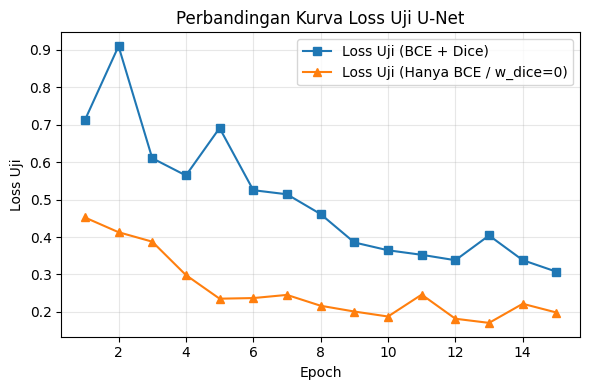

In [13]:
#=== Plot Perbandingan Kurva Loss Uji (BCE + Dice vs Hanya BCE) ===
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["test"]) + 1)
plt.plot(ep, hist_unet["test"], "s-", label="Loss Uji (BCE + Dice)")
plt.plot(ep, hist_unet_bce["test"], "^-", label="Loss Uji (Hanya BCE / w_dice=0)")
plt.xlabel("Epoch")
plt.ylabel("Loss Uji")
plt.title("Perbandingan Kurva Loss Uji U-Net")
plt.legend()
plt.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d2_perbandingan_kurva_bce.png", dpi=120)
plt.show()

Praktikum D3: Metrik Evaluasi Segmentasi

In [10]:
# === D3.1 Fungsi metrik dan evaluasi ===
@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()
    TP = FP = FN = TN = 0; iou_per_citra = []
    for x, y, v in dl_test:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        pred = (torch.sigmoid(forward(model, x)) > thr).float()
        tp = (pred * y * v).sum(dim=(1, 2, 3)); fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3)); tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))
        TP += tp.sum().item(); FP += fp.sum().item(); FN += fn.sum().item(); TN += tn.sum().item()
        iou_per_citra += (tp / (tp + fp + fn).clamp_min(1)).tolist()
    iou_fg = TP / (TP + FP + FN); iou_bg = TN / (TN + FN + FP)
    return {"IoU_hewan": iou_fg, "IoU_latar": iou_bg, "mIoU": (iou_fg + iou_bg) / 2,
            "Dice": 2 * TP / (2 * TP + FP + FN), "PixelAcc": (TP + TN) / (TP + TN + FP + FN),
            "iou_per_citra": iou_per_citra}

def ringkas(m):
    return {k: round(v, 4) for k, v in m.items() if k != "iou_per_citra"}

HASIL = {}
HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)
print(ringkas(HASIL["U-Net (dari nol)"]))

{'IoU_hewan': 0.8252, 'IoU_latar': 0.9027, 'mIoU': 0.8639, 'Dice': 0.9042, 'PixelAcc': 0.9333}


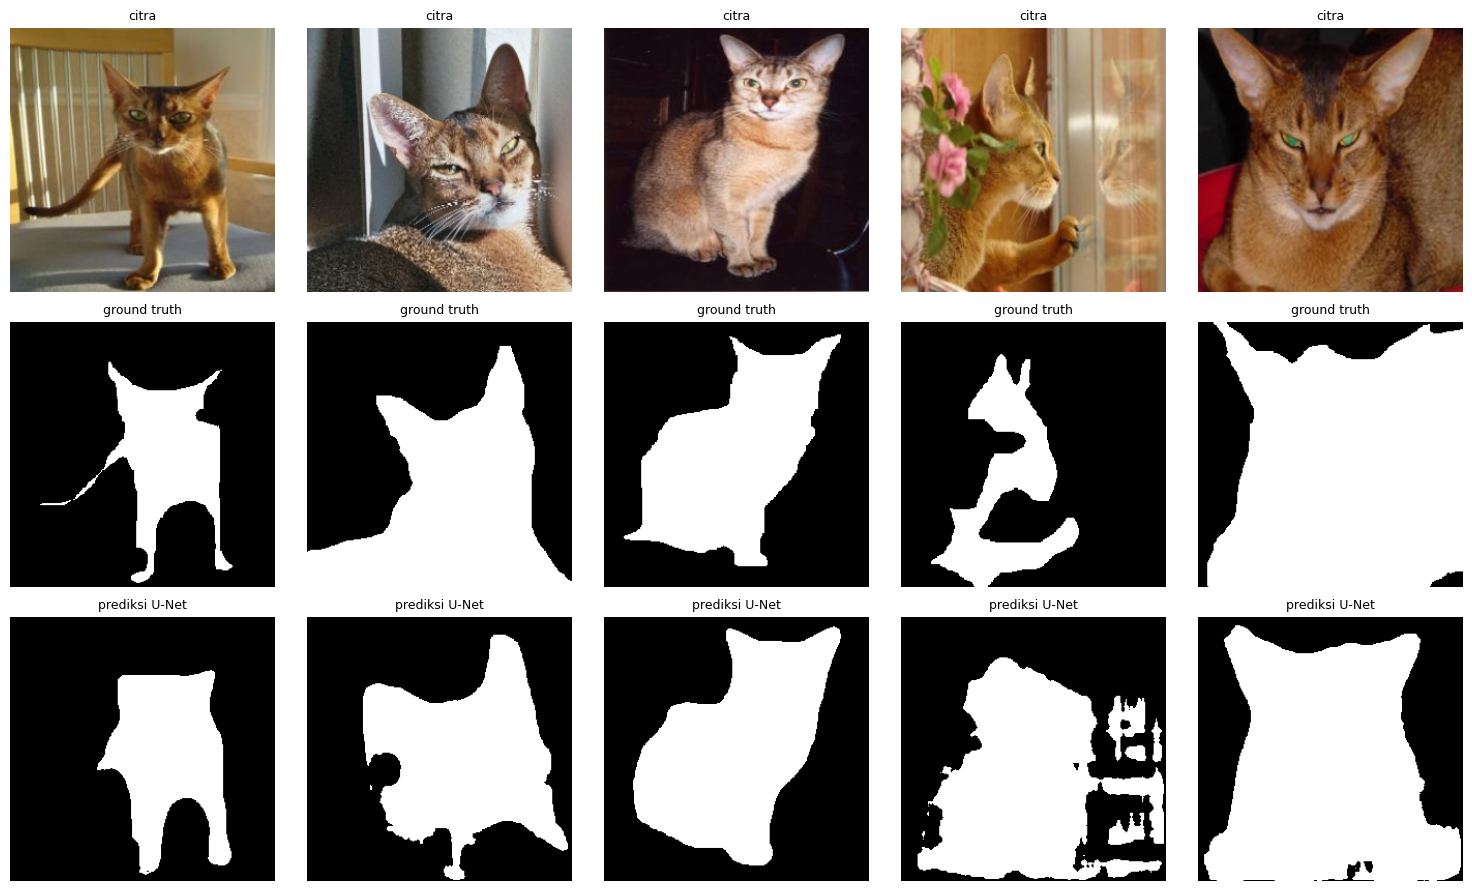

In [25]:
# === D3.2 Visualisasi prediksi U-Net ===
@torch.no_grad()
def prediksi(model, forward, idx):
    x = torch.stack([ds_test[i][0] for i in idx]).to(DEVICE)
    return (torch.sigmoid(forward(model, x)) > 0.5).float().cpu()

idx_vis = [0, 1, 2, 3, 4]
p_unet = prediksi(unet, fwd_unet, idx_vis)
fig, ax = plt.subplots(3, len(idx_vis), figsize=(3 * len(idx_vis), 9))
for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title("citra", fontsize=9)
    ax[1, j].imshow(y[0], cmap="gray"); ax[1, j].set_title("ground truth", fontsize=9)
    ax[2, j].imshow(p_unet[j, 0], cmap="gray"); ax[2, j].set_title("prediksi U-Net", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d3_prediksi_unet.png",
dpi=120); plt.show()

In [15]:
#=== Eksperimen Tugas Kecil D3: Mengubah Ambang (thr) ===
print("Evaluasi U-Net dengan thr = 0.3:")
hasil_thr03 = evaluasi(unet, fwd_unet, thr=0.3)
print(ringkas(hasil_thr03))

print("\nEvaluasi U-Net dengan thr = 0.7:")
hasil_thr07 = evaluasi(unet, fwd_unet, thr=0.7)
print(ringkas(hasil_thr07))

Evaluasi U-Net dengan thr = 0.3:
{'IoU_hewan': 0.8183, 'IoU_latar': 0.8944, 'mIoU': 0.8563, 'Dice': 0.9001, 'PixelAcc': 0.9284}

Evaluasi U-Net dengan thr = 0.7:
{'IoU_hewan': 0.8208, 'IoU_latar': 0.9043, 'mIoU': 0.8625, 'Dice': 0.9016, 'PixelAcc': 0.9335}


Praktikum D4: Transfer Learning dengan DeepLabV3

In [11]:
# === D4.1 Muat DeepLabV3 pra-latih dan ganti kepala klasifikasi ===
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large, DeepLabV3_MobileNet_V3_Large_Weights

set_seed(42)
dlv3 = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)   # 21 kelas VOC -> 1 kanal
dlv3.aux_classifier = None
dlv3 = dlv3.to(DEVICE)

print("Jumlah parameter DeepLabV3-MobileNetV3: %.2f juta" % (sum(p.numel() for p in dlv3.parameters()) / 1e6))
fwd_dlv3 = lambda m, x: m(x)["out"]
groups = [{"params": dlv3.backbone.parameters(), "lr": 1e-4}, # backbone: lr kecil
 {"params": dlv3.classifier.parameters(), "lr": 1e-3}]   # kepala baru: lr besar

hist_dlv3 = latih(dlv3, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3 MobileNetV3 (pra-latih)", param_groups=groups)
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(dlv3, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))

Jumlah parameter DeepLabV3-MobileNetV3: 11.02 juta
[DeepLabV3 MobileNetV3 (pra-latih)] epoch 1/6  loss latih 0.1819  loss uji 0.1294 (22 s)
[DeepLabV3 MobileNetV3 (pra-latih)] epoch 2/6  loss latih 0.0924  loss uji 0.1251 (45 s)
[DeepLabV3 MobileNetV3 (pra-latih)] epoch 3/6  loss latih 0.0718  loss uji 0.1035 (67 s)
[DeepLabV3 MobileNetV3 (pra-latih)] epoch 4/6  loss latih 0.0587  loss uji 0.1062 (89 s)
[DeepLabV3 MobileNetV3 (pra-latih)] epoch 5/6  loss latih 0.0528  loss uji 0.1108 (112 s)
[DeepLabV3 MobileNetV3 (pra-latih)] epoch 6/6  loss latih 0.0449  loss uji 0.1024 (134 s)
{'IoU_hewan': 0.9537, 'IoU_latar': 0.9754, 'mIoU': 0.9645, 'Dice': 0.9763, 'PixelAcc': 0.9837}


In [16]:
# === Tugas Kecil D4: Membekukan Backbone DeepLabV3 ===
set_seed(42)
dlv3_frozen = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3_frozen.classifier[4] = nn.Conv2d(256, 1, kernel_size=1)
dlv3_frozen.aux_classifier = None

# Membekukan parameter backbone
for param in dlv3_frozen.backbone.parameters():
    param.requires_grad = False

dlv3_frozen = dlv3_frozen.to(DEVICE)
fwd_dlv3_frozen = lambda m, x: m(x)["out"]

# Melatih model dengan backbone yang dibekukan
hist_dlv3_frozen = latih(dlv3_frozen, fwd_dlv3_frozen, CFG["EP_DLV3"], 1e-3, "DeepLabV3 (Frozen)")
HASIL["DeepLabV3 (Frozen)"] = evaluasi(dlv3_frozen, fwd_dlv3_frozen)
print(ringkas(HASIL["DeepLabV3 (Frozen)"]))

[DeepLabV3 (Frozen)] epoch 1/6  loss latih 0.2182  loss uji 0.1420 (13 s)
[DeepLabV3 (Frozen)] epoch 2/6  loss latih 0.1440  loss uji 0.1516 (27 s)
[DeepLabV3 (Frozen)] epoch 3/6  loss latih 0.1285  loss uji 0.1399 (41 s)
[DeepLabV3 (Frozen)] epoch 4/6  loss latih 0.1107  loss uji 0.1386 (54 s)
[DeepLabV3 (Frozen)] epoch 5/6  loss latih 0.1015  loss uji 0.1403 (67 s)
[DeepLabV3 (Frozen)] epoch 6/6  loss latih 0.0943  loss uji 0.1535 (80 s)
{'IoU_hewan': 0.9253, 'IoU_latar': 0.9596, 'mIoU': 0.9425, 'Dice': 0.9612, 'PixelAcc': 0.9731}


Praktikum D5: Fine-Tuning SegFormer-B0

In [17]:
# === D5.1 Muat SegFormer-B0 dan latih ===
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()

set_seed(42)
segf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0",
num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B0: %.2f juta" % (sum(p.numel() for p in segf.parameters()) / 1e6))

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits                       # resolusi 1/4 dari input
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf = latih(segf, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B0 (pralatih)")
HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(segf, fwd_segf)
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B0: 3.71 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pralatih)] epoch 1/6  loss latih 0.3138  loss uji 0.1549 (28 s)
[SegFormer-B0 (pralatih)] epoch 2/6  loss latih 0.1429  loss uji 0.1366 (55 s)
[SegFormer-B0 (pralatih)] epoch 3/6  loss latih 0.1072  loss uji 0.1131 (81 s)
[SegFormer-B0 (pralatih)] epoch 4/6  loss latih 0.0811  loss uji 0.1125 (108 s)
[SegFormer-B0 (pralatih)] epoch 5/6  loss latih 0.0670  loss uji 0.1190 (134 s)
[SegFormer-B0 (pralatih)] epoch 6/6  loss latih 0.0919  loss uji 0.1943 (160 s)
{'IoU_hewan': 0.9038, 'IoU_latar': 0.9457, 'mIoU': 0.9248, 'Dice': 0.9495, 'PixelAcc': 0.964}


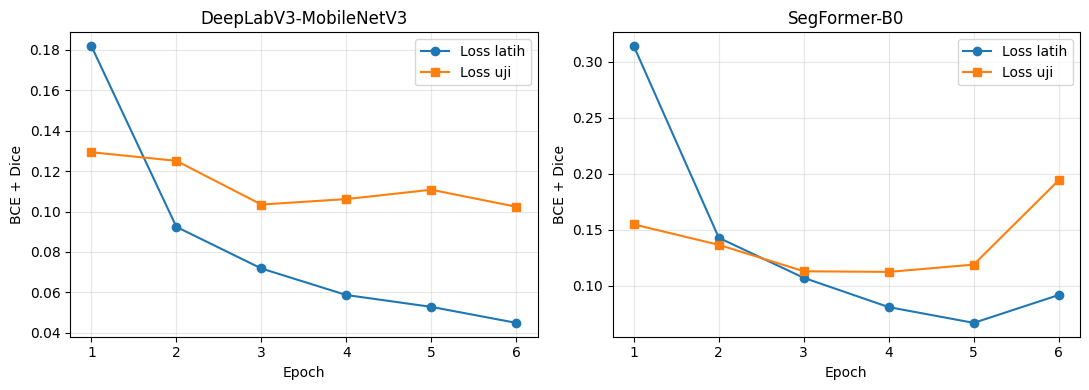

In [18]:
# === D5.2 Kurva loss model pra-latih ===
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("DeepLabV3-MobileNetV3", hist_dlv3), ("SegFormer-B0", hist_segf)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih");
    a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama);
    a.set_xlabel("Epoch");
    a.set_ylabel("BCE + Dice");
    a.legend();
    a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d5_kurva_pralatih.png",
dpi=120); plt.show()

In [19]:
# === Tugas Kecil D5: Fine-Tuning SegFormer-B1 ===
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()

set_seed(42)
segf_b1 = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b1", num_labels=1).to(DEVICE)
print("Jumlah parameter SegFormer-B1: %.2f juta" % (sum(p.numel() for p in segf_b1.parameters()) / 1e6))

def fwd_segf_b1(m, x):
    logit = m(pixel_values=x).logits
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf_b1 = latih(segf_b1, fwd_segf_b1, CFG["EP_SEGF"], 3e-4, "SegFormer-B1 (pra-latih)")
HASIL["SegFormer-B1 (pra-latih)"] = evaluasi(segf_b1, fwd_segf_b1)
print(ringkas(HASIL["SegFormer-B1 (pra-latih)"]))

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 54.7MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Jumlah parameter SegFormer-B1: 13.68 juta


model.safetensors: reconstructing file:   0%|          |  0.00B / 54.7MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B1 (pra-latih)] epoch 1/6  loss latih 0.2840  loss uji 0.1648 (44 s)
[SegFormer-B1 (pra-latih)] epoch 2/6  loss latih 0.1241  loss uji 0.1142 (88 s)
[SegFormer-B1 (pra-latih)] epoch 3/6  loss latih 0.0947  loss uji 0.1652 (132 s)
[SegFormer-B1 (pra-latih)] epoch 4/6  loss latih 0.0717  loss uji 0.0934 (176 s)
[SegFormer-B1 (pra-latih)] epoch 5/6  loss latih 0.0570  loss uji 0.1017 (220 s)
[SegFormer-B1 (pra-latih)] epoch 6/6  loss latih 0.0492  loss uji 0.1124 (264 s)
{'IoU_hewan': 0.9431, 'IoU_latar': 0.9701, 'mIoU': 0.9566, 'Dice': 0.9707, 'PixelAcc': 0.98}


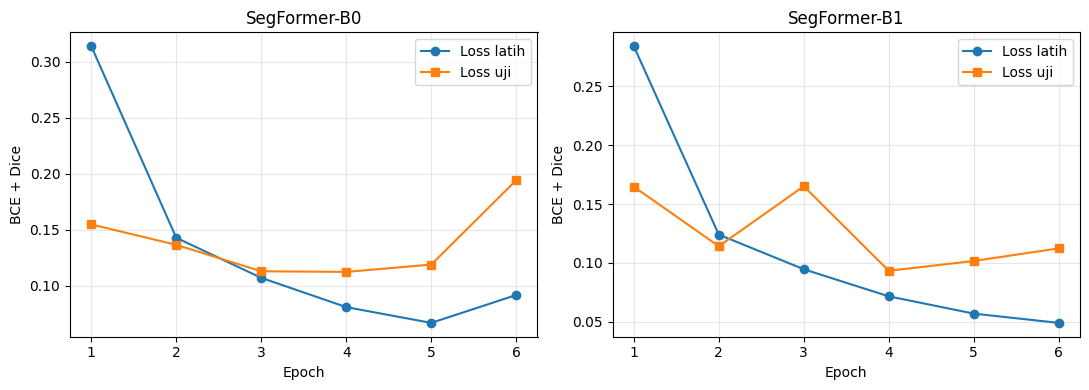

In [20]:
# === Kurva Loss Perbandingan SegFormer-B0 dan SegFormer-B1 ===
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("SegFormer-B0", hist_segf), ("SegFormer-B1", hist_segf_b1)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih")
    a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama)
    a.set_xlabel("Epoch")
    a.set_ylabel("BCE + Dice")
    a.legend()
    a.grid(alpha=.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_d5_kurva_b0_b1.png", dpi=120)
plt.show()

Praktikum D6: Perbandingan Model dan Analisis Kesalahan

In [21]:
# === D6.1 Tabel perbandingan (Aman dari KeyError) ===
import pandas as pd

param = {
    "U-Net (dari nol)": unet,
    "DeepLabV3-MobileNetV3 (pra-latih)": dlv3,
    "SegFormer-B0 (pra-latih)": segf
}

tabel_data = []
for k, v in HASIL.items():
    if k in param:
        waktu_latih = WAKTU.get(k, 0)
        if waktu_latih == 0:
            for wk, wv in WAKTU.items():
                if k.split()[0] in wk:
                    waktu_latih = wv
                    break

        tabel_data.append({
            "Model": k,
            **ringkas(v),
            "Waktu latih (s)": round(waktu_latih, 1)
        })

tabel = pd.DataFrame(tabel_data)
print(tabel.to_string(index=False))

tabel.to_csv(f"{FIG_DIR}/js05_tabel_hasil.csv", index=False)
with open(f"{FIG_DIR}/js05_hasil.json", "w") as f:
    json.dump({
        "perangkat": DEVICE,
        "mode": "CEPAT" if CEPAT else "PENUH",
        "cfg": CFG,
        "hasil": {k: ringkas(v) for k, v in HASIL.items() if k in param},
        "waktu_detik": {k: WAKTU.get(k, 0) for k in param}
    }, f, indent=2)

                            Model  IoU_hewan  IoU_latar   mIoU   Dice  PixelAcc  Waktu latih (s)
                 U-Net (dari nol)     0.8252     0.9027 0.8639 0.9042    0.9333            733.3
DeepLabV3-MobileNetV3 (pra-latih)     0.9537     0.9754 0.9645 0.9763    0.9837              0.0
         SegFormer-B0 (pra-latih)     0.9038     0.9457 0.9248 0.9495    0.9640            160.5


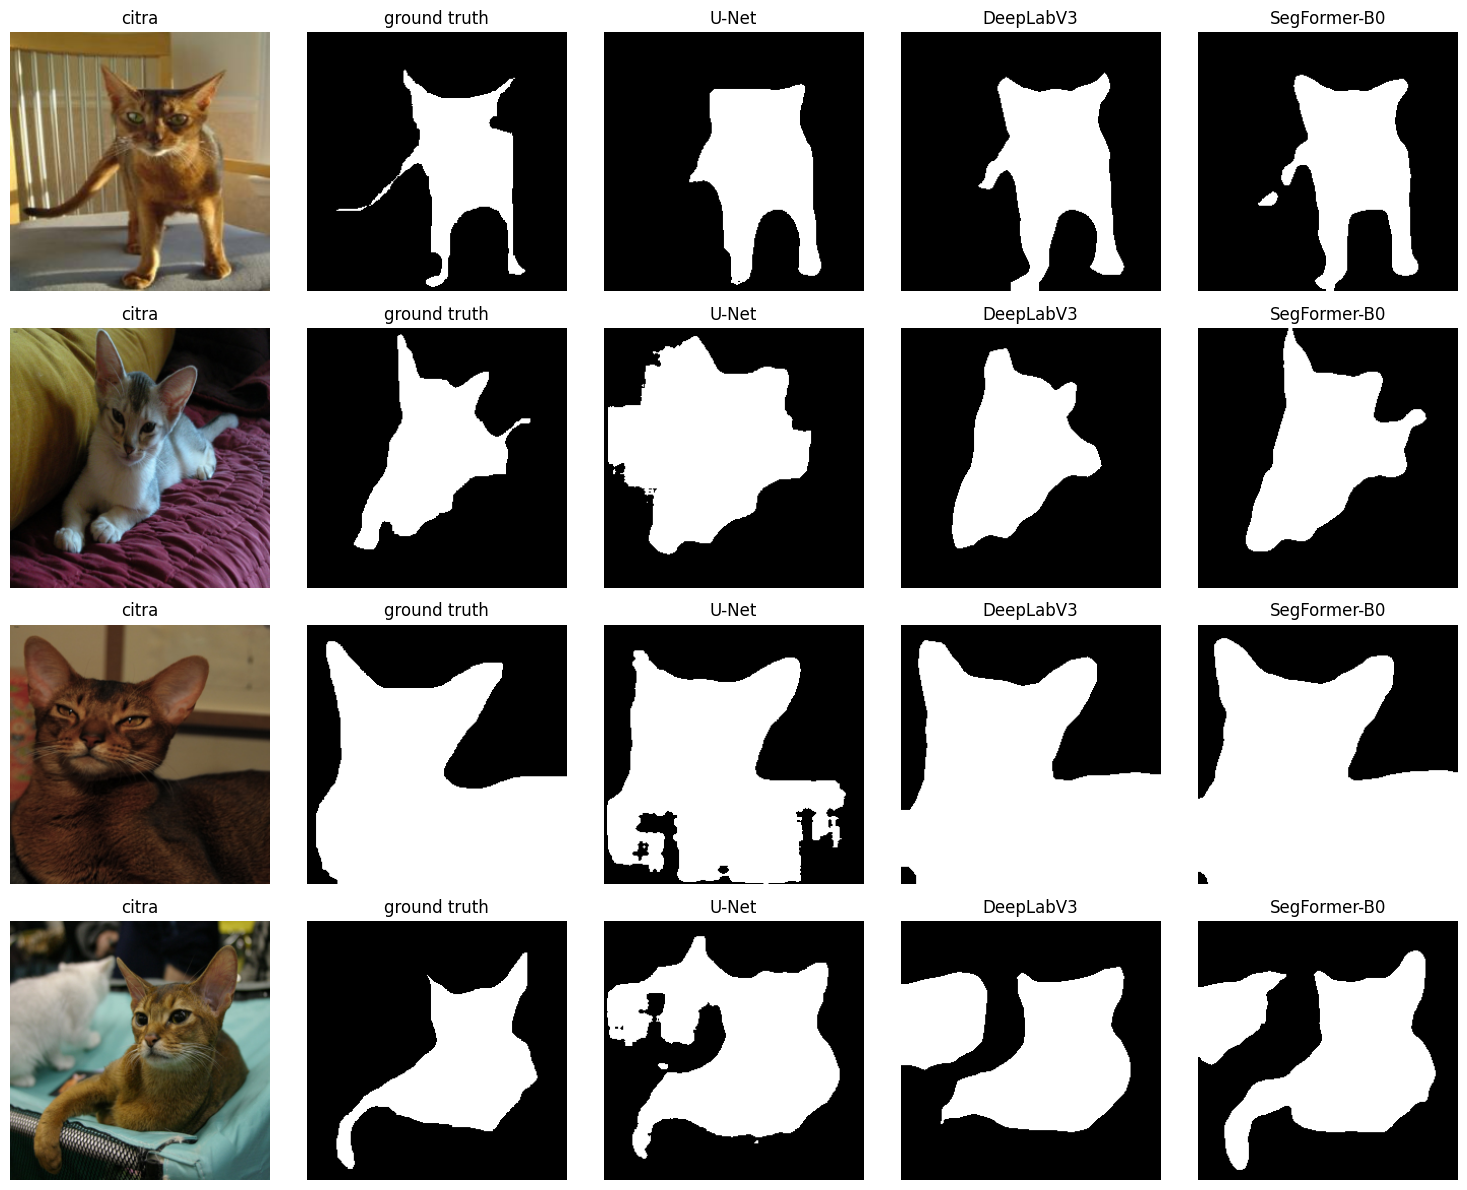

In [26]:
# === D6.2 Contoh prediksi ketiga model ===
model_fwd = [("U-Net", unet, fwd_unet), ("DeepLabV3", dlv3, fwd_dlv3), ("SegFormer-B0", segf, fwd_segf)]
idx_vis = [0, 5, 10, 15]
fig, ax = plt.subplots(len(idx_vis), 5, figsize=(15, 3 * len(idx_vis)))
preds = {n: prediksi(m, f, idx_vis) for n, m, f in model_fwd}
for r, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[r, 0].imshow(denorm(x)); ax[r, 1].imshow(y[0], cmap="gray")
    ax[r, 0].set_title("citra"); ax[r, 1].set_title("ground truth")
    for c, (n, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(preds[n][r, 0], cmap="gray"); ax[r, c + 2].set_title(n)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_perbandingan.png",
dpi=110); plt.show()

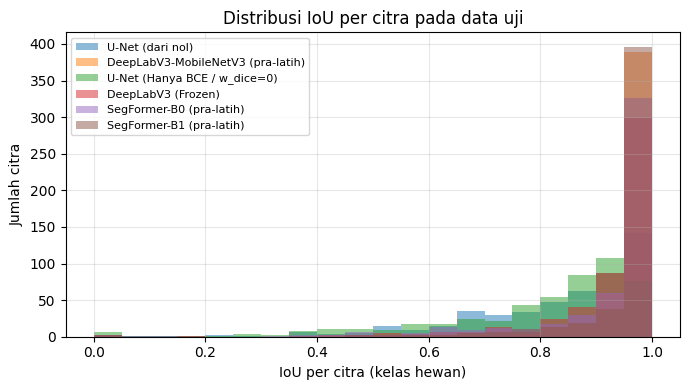

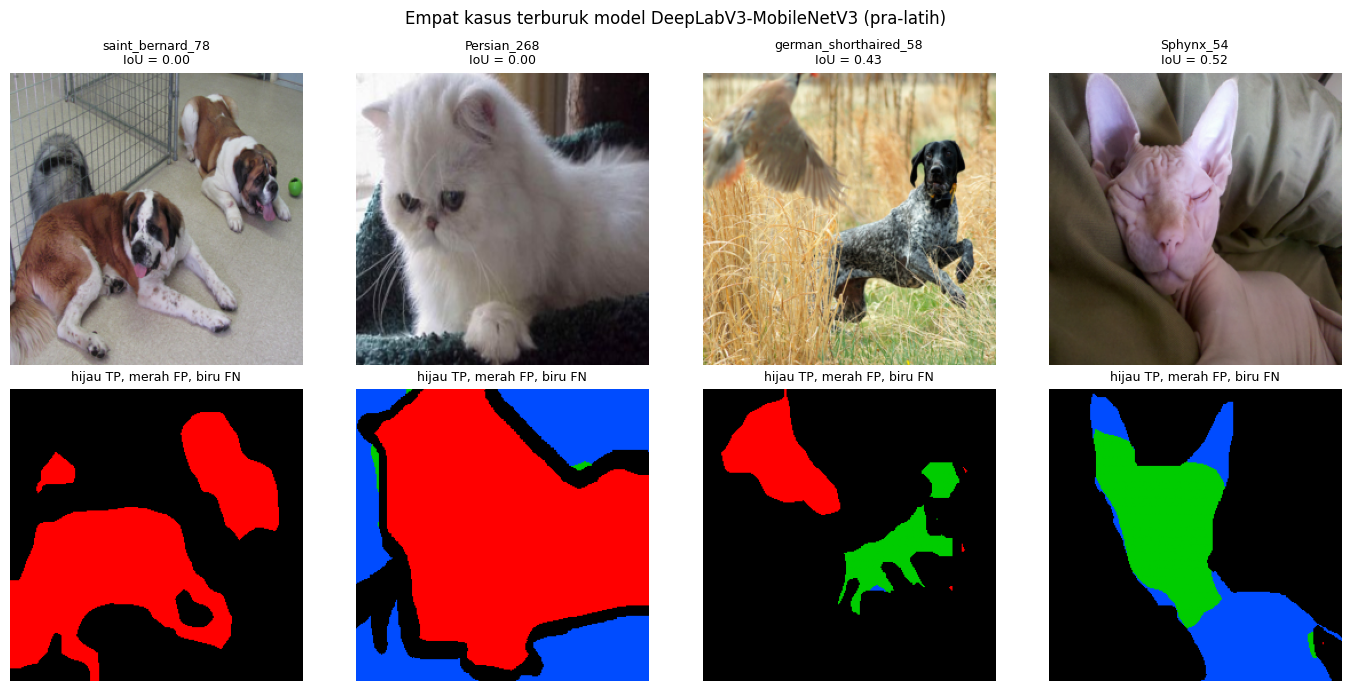

Model terbaik: DeepLabV3-MobileNetV3 (pra-latih) | IoU terendah: [0.0, 0.004, 0.425, 0.525]


In [27]:
# === D6.3 Analisis kesalahan: distribusi IoU per citra dan kasus terburuk ===
plt.figure(figsize=(7, 4))
for n, m in HASIL.items():
    plt.hist(m["iou_per_citra"], bins=20, range=(0, 1), alpha=.5, label=n)
plt.xlabel("IoU per citra (kelas hewan)"); plt.ylabel("Jumlah citra");
plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Distribusi IoU per citra pada data uji")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_histogram_iou.png", dpi=120); plt.show()

terbaik = max(HASIL, key=lambda k: HASIL[k]["mIoU"])
mdl, fw = {n: (m, f) for n, m, f in [("U-Net (dari nol)", unet, fwd_unet),
 ("DeepLabV3-MobileNetV3 (pra-latih)", dlv3, fwd_dlv3), ("SegFormer-B0 (pralatih)", segf, fwd_segf)]}[terbaik]
iou = np.array(HASIL[terbaik]["iou_per_citra"]); buruk = np.argsort(iou)[:4].tolist()
pb = prediksi(mdl, fw, buruk)
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate(buruk):
  x, y, v = ds_test[i]; p = pb[j, 0]; g = y[0]; val = v[0]
  peta = np.zeros((*g.shape, 3))
  peta[((p == 1) & (g == 1) & (val == 1)).numpy()] = [0, .8, 0]
  peta[((p == 1) & (g == 0) & (val == 1)).numpy()] = [1, 0, 0]
  peta[((p == 0) & (g == 1) & (val == 1)).numpy()] = [0, .3, 1]
  ax[0, j].imshow(denorm(x)); ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
  ax[1, j].imshow(peta); ax[1, j].set_title("hijau TP, merah FP, biru FN", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Empat kasus terburuk model {terbaik}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk.png", dpi=110); plt.show()
print("Model terbaik:", terbaik, "| IoU terendah:", np.round(iou[buruk], 3).tolist())

Penugasan No. 4

In [31]:
# === Penugasan No. 4: Eksperimen Penambahan Epoch pada DeepLabV3 ===
import torchvision
set_seed(42)

dlv3_tuning = torchvision.models.segmentation.deeplabv3_mobilenet_v3_large(
    weights=torchvision.models.segmentation.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
)
dlv3_tuning.classifier[4] = torch.nn.Conv2d(256, 1, kernel_size=(1, 1))
dlv3_tuning.aux_classifier = None
dlv3_tuning = dlv3_tuning.to(DEVICE)

# Parameter groups untuk fine-tuning backbone dan classifier
groups = [
    {"params": dlv3_tuning.backbone.parameters(), "lr": 1e-4},
    {"params": dlv3_tuning.classifier.parameters(), "lr": 1e-3}
]

waktu_mulai = time.time()

hist_dlv3_tuning = latih(
    dlv3_tuning,
    fwd_dlv3,
    12,
    1e-3,
    "DeepLabV3 (Tuning 12 Epoch)",
    param_groups=groups
)
WAKTU["DeepLabV3 (Tuning 12 Epoch)"] = time.time() - waktu_mulai

# Evaluasi hasil akhir
HASIL["DeepLabV3 (Tuning 12 Epoch)"] = evaluasi(dlv3_tuning, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3 (Tuning 12 Epoch)"]))

[DeepLabV3 (Tuning 12 Epoch)] epoch 1/12  loss latih 0.1819  loss uji 0.1292 (23 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 2/12  loss latih 0.0925  loss uji 0.1255 (45 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 3/12  loss latih 0.0719  loss uji 0.1029 (67 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 4/12  loss latih 0.0590  loss uji 0.1062 (89 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 5/12  loss latih 0.0525  loss uji 0.1114 (112 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 6/12  loss latih 0.0446  loss uji 0.1039 (134 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 7/12  loss latih 0.0455  loss uji 0.1159 (156 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 8/12  loss latih 0.0431  loss uji 0.1138 (179 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 9/12  loss latih 0.0347  loss uji 0.1197 (201 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 10/12  loss latih 0.0324  loss uji 0.1104 (223 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 11/12  loss latih 0.0316  loss uji 0.1120 (246 s)
[DeepLabV3 (Tuning 12 Epoch)] epoch 12/12  loss latih 0.0263  loss 

Penugasan No. 5

Silakan unggah 3 foto hewan peliharaan:


Saving kucing1.jpeg to kucing1 (6).jpeg
Saving kucing2.jpeg to kucing2 (6).jpeg
Saving kucing3.jpeg to kucing3 (6).jpeg


/tmp/ipykernel_1176/3650587675.py:42: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img_overlay = Image.alpha_composite(img_pil.convert("RGBA"), Image.fromarray(overlay_rgba, "RGBA"))


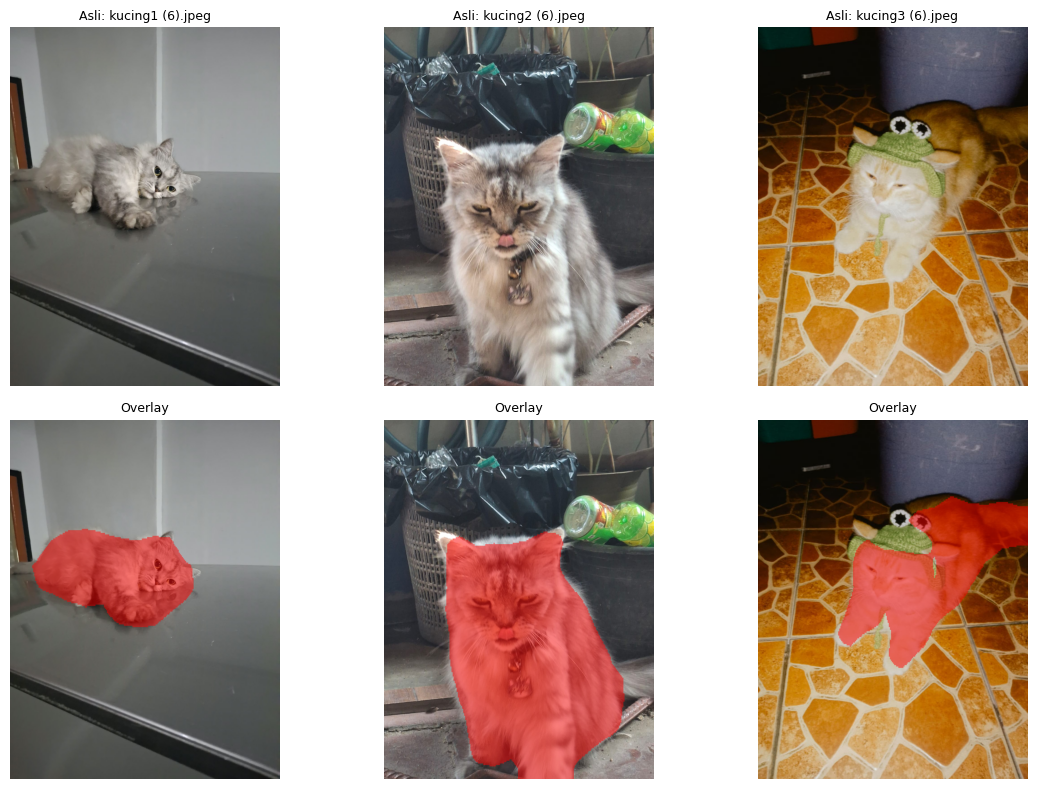

In [38]:
# === Penugasan No. 5: Inferensi Foto Hewan Peliharaan Sendiri ===
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image
import torch
import torchvision.transforms as T
import numpy as np

print("Silakan unggah 3 foto hewan peliharaan:")
uploaded = files.upload()

# Transformasi citra agar sesuai dengan input model
transform_inf = T.Compose([
    T.Resize((256, 256)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

model_terbaik = dlv3_tuning.eval()
image_filenames = list(uploaded.keys())[:3]
n_imgs = len(image_filenames)

fig, ax = plt.subplots(2, n_imgs, figsize=(4 * n_imgs, 8))
if n_imgs == 1:
    ax = np.array([[ax], [ax]])

for idx, filename in enumerate(image_filenames):
    img_pil = Image.open(filename).convert("RGB")
    x_tensor = transform_inf(img_pil).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output = fwd_dlv3(model_terbaik, x_tensor)
        pred_mask = (torch.sigmoid(output) > 0.5).float().cpu().numpy()[0, 0]

    # Resize mask kembali ke ukuran asli citra
    mask_resized = Image.fromarray((pred_mask * 255).astype(np.uint8)).resize(img_pil.size, Image.NEAREST)
    mask_arr = np.array(mask_resized) > 127

    # Membuat overlay warna merah transparan hanya pada bagian kucing
    overlay_rgba = np.zeros((*img_pil.size[::-1], 4), dtype=np.uint8)
    overlay_rgba[mask_arr] = [255, 0, 0, 128]  # Merah dengan transparan 50%
    img_overlay = Image.alpha_composite(img_pil.convert("RGBA"), Image.fromarray(overlay_rgba, "RGBA"))

    # Baris 0: Tampilkan Citra Asli berjajar ke samping
    ax[0, idx].imshow(img_pil)
    ax[0, idx].set_title(f"Asli: {filename}", fontsize=9)
    ax[0, idx].axis("off")

    # Baris 1: Tampilkan Hasil Overlay tepat di bawah foto aslinya
    ax[1, idx].imshow(img_overlay)
    ax[1, idx].set_title("Overlay", fontsize=9)
    ax[1, idx].axis("off")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js05_penugasan_hewan_sendiri.png", dpi=110)
plt.show()